In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import os

In [9]:
# 1. Dataset path load karein
file_path = "../data/raw/MERGED_CSV/Merged01.csv"
print(f"Checking path: {file_path}")

if not os.path.exists(file_path):
    # Agar notebook root context se chal rahi ho toh alternative check
    file_path = "data/raw/MERGED_CSV/Merged01.csv"

print(f"Loading dataset from: {file_path}")
df = pd.read_csv(file_path)
print(f"Original shape: {df.shape}")

Checking path: ../data/raw/MERGED_CSV/Merged01.csv
Loading dataset from: ../data/raw/MERGED_CSV/Merged01.csv
Original shape: (712311, 40)


In [10]:
# 2. Cleaning & Null / Inf Handling
label_col = 'Label' if 'Label' in df.columns else 'label'
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# Features & target alag karein
X = df.drop(columns=[label_col])
y = df[label_col]

# Timestamp / non-numerical metadata remove karein agar present ho
for col in ['ts', 'timestamp', 'Time']:
    if col in X.columns:
        X = X.drop(columns=[col])

le = LabelEncoder()
y_encoded = le.fit_transform(y)
print(f"Cleaned feature space: {X.shape}")
print(f"Number of classes: {len(np.unique(y_encoded))}")

Cleaned feature space: (712297, 39)
Number of classes: 34


In [11]:
# 3. Stratified sample for fast edge computation (50,000 samples)
X_sample, _, y_sample, _ = train_test_split(
    X, y_encoded, train_size=50000, stratify=y_encoded, random_state=42
)

In [12]:
# 4. Feature Importance Calculation via Random Forest
print("Training Random Forest model for feature ranking...")
rf = RandomForestClassifier(n_estimators=40, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_sample, y_sample)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top_12 = importances.head(12)

print("\n" + "="*45)
print("  TOP 12 FINALIZED RUNTIME FEATURES")
print("="*45)
for rank, (feat, score) in enumerate(top_12.items(), start=1):
    print(f"{rank:2d}. {feat:<25} (Importance: {score:.4f})")

Training Random Forest model for feature ranking...

  TOP 12 FINALIZED RUNTIME FEATURES
 1. ICMP                      (Importance: 0.1192)
 2. TCP                       (Importance: 0.0799)
 3. UDP                       (Importance: 0.0724)
 4. Protocol Type             (Importance: 0.0694)
 5. psh_flag_number           (Importance: 0.0647)
 6. syn_flag_number           (Importance: 0.0597)
 7. syn_count                 (Importance: 0.0594)
 8. ack_count                 (Importance: 0.0523)
 9. Header_Length             (Importance: 0.0477)
10. fin_count                 (Importance: 0.0416)
11. fin_flag_number           (Importance: 0.0384)
12. rst_flag_number           (Importance: 0.0377)


C:\Users\suraj\AppData\Local\Temp\ipykernel_13372\852005895.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_12.values, y=top_12.index, palette="mako")



Feature importance plot saved to: ../docs/diagrams\top_12_features_importance.png


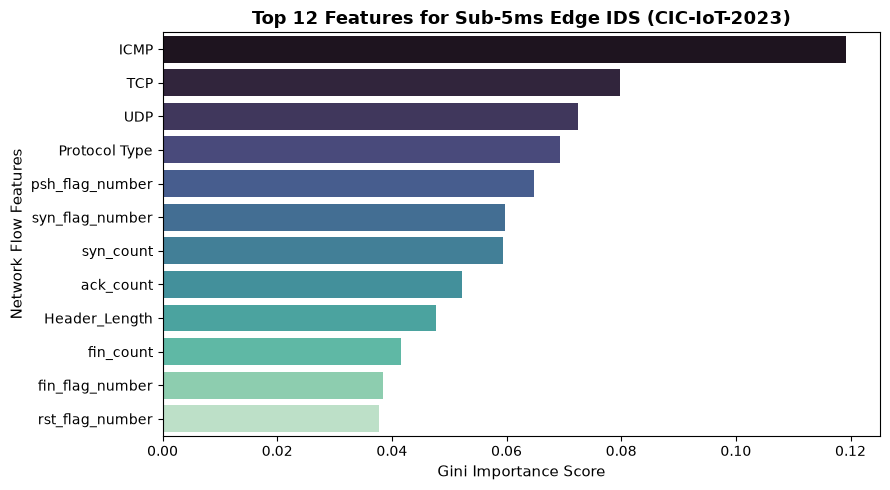

In [13]:
# 5. Export Feature Importance Plot for Presentation (Slide 6)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_12.values, y=top_12.index, palette="mako")
plt.title("Top 12 Features for Sub-5ms Edge IDS (CIC-IoT-2023)", fontsize=13, fontweight='bold')
plt.xlabel("Gini Importance Score", fontsize=11)
plt.ylabel("Network Flow Features", fontsize=11)
plt.tight_layout()

# Save diagram
save_dir = "../docs/diagrams" if os.path.exists("../docs") else "docs/diagrams"
os.makedirs(save_dir, exist_ok=True)
plot_path = os.path.join(save_dir, "top_12_features_importance.png")
plt.savefig(plot_path, dpi=300)
print(f"\nFeature importance plot saved to: {plot_path}")

In [14]:
# 6. Export reduced 12-feature sample for Member 2 benchmarking
selected_cols = list(top_12.index)
df_reduced = X_sample[selected_cols].copy()
df_reduced['Label'] = le.inverse_transform(y_sample)

proc_dir = "../data/processed" if os.path.exists("../data") else "data/processed"
os.makedirs(proc_dir, exist_ok=True)
csv_out_path = os.path.join(proc_dir, "top12_features_sample.csv")
df_reduced.to_csv(csv_out_path, index=False)
print(f"Reduced dataset saved to: {csv_out_path}")

Reduced dataset saved to: ../data/processed\top12_features_sample.csv


C:\Users\suraj\AppData\Local\Temp\ipykernel_13372\4142001633.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_attacks.values, y=top_attacks.index, palette="flare")


Saved: docs/diagrams/eda_class_distribution.png


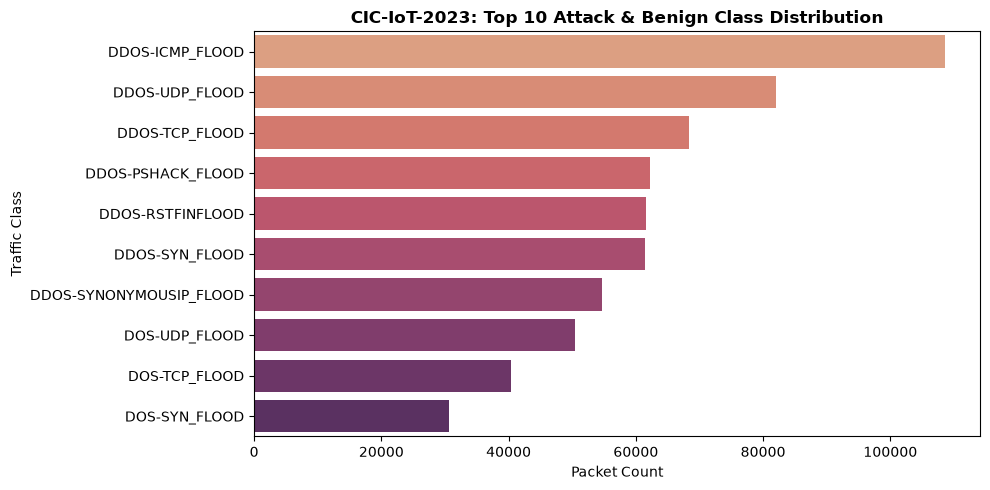

In [15]:
# ---------------------------------------------------------
# EDA 1: CLASS DISTRIBUTION (ATTACK TYPES BREAKDOWN)
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
top_attacks = df['Label'].value_counts().head(10)
sns.barplot(x=top_attacks.values, y=top_attacks.index, palette="flare")
plt.title("CIC-IoT-2023: Top 10 Attack & Benign Class Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Packet Count", fontsize=10)
plt.ylabel("Traffic Class", fontsize=10)
plt.tight_layout()

plt.savefig("../docs/diagrams/eda_class_distribution.png", dpi=300)
print("Saved: docs/diagrams/eda_class_distribution.png")

Saved: docs/diagrams/eda_feature_correlation.png


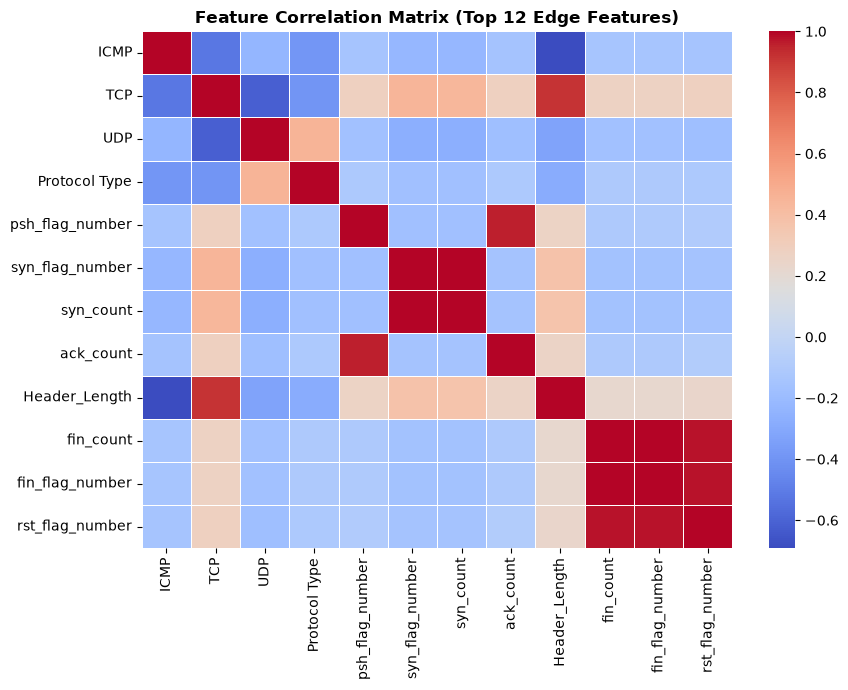

In [16]:
# ---------------------------------------------------------
# EDA 2: FEATURE CORRELATION HEATMAP (TOP 12 FEATURES)
# ---------------------------------------------------------
plt.figure(figsize=(9, 7))
corr_matrix = df_reduced[selected_cols].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, linewidths=0.5)
plt.title("Feature Correlation Matrix (Top 12 Edge Features)", fontsize=12, fontweight='bold')
plt.tight_layout()

plt.savefig("../docs/diagrams/eda_feature_correlation.png", dpi=300)
print("Saved: docs/diagrams/eda_feature_correlation.png")